# Лабораторная работа 2. Кластерный анализ методом k-средних

### Задание
Для каждого набора данных:

1. определить число кластеров и обосновать свой выбор;
2. разбить объекты на кластеры, предложить и обосновать интерпретацию кластеров.

### План
Часть A (леденцы) и часть B (цифры): разведочный анализ → критерии выбора k (метод локтя, силуэт, Calinski–Harabasz, Davies–Bouldin, gap-статистика, устойчивость; для цифр дополнительно BIC смеси Бернулли) → итоговое разбиение → интерпретация.

## 0. Подготовка окружения и загрузка данных

In [1]:
import sys, platform, warnings, zipfile, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from IPython.display import display

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import FactorAnalysis
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10, "axes.titlesize": 11, "figure.max_open_warning": 0})
pd.set_option("display.width", 160, "display.max_columns", 40, "display.precision", 3)

In [2]:
CANDY_PATH = "/content/Леденцы.dat"
DIGITS_PATH = "/content/digit.dat"

print("Леденцы:", CANDY_PATH, "| Цифры:", DIGITS_PATH)

Леденцы: /content/Леденцы.dat | Цифры: /content/digit.dat


In [3]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
FIG_PREFIX = "fig"

def save_show(fig, name, tight=True):
    if tight:
        fig.tight_layout()
    fig.savefig(FIG_DIR / f"{FIG_PREFIX}_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def heatmap(ax, M, xt, yt, fmt="{:.2f}", cmap="RdBu_r", vmin=None, vmax=None, annot=True, fontsize=8):
    M = np.asarray(M, float)
    vmin = np.nanmin(M) if vmin is None else vmin
    vmax = np.nanmax(M) if vmax is None else vmax
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt, rotation=45, ha="right")
    ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt)
    ax.grid(False)
    if annot:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                t = (M[i, j] - vmin) / (vmax - vmin + 1e-12)
                ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=fontsize,
                        color="white" if (t < 0.2 or t > 0.8) else "black")
    return im

In [4]:
def internal_scores(X, labels, metric="euclidean"):
    return dict(silhouette=silhouette_score(X, labels, metric=metric),
                calinski_harabasz=calinski_harabasz_score(X, labels),
                davies_bouldin=davies_bouldin_score(X, labels))

def fit_kmeans(X, k, n_init=50, seed=SEED):
    return KMeans(n_clusters=k, n_init=n_init, init="k-means++", random_state=seed).fit(X)

def gap_statistic(X, ks, B=50, seed=SEED):
    rng = np.random.default_rng(seed)
    Xc = X - X.mean(0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    Xp = Xc @ Vt.T
    lo, hi = Xp.min(0), Xp.max(0)
    def logW(M, k):
        return np.log(KMeans(k, n_init=5, random_state=seed).fit(M).inertia_)
    obs = np.array([logW(Xp, k) for k in ks])
    ref = np.array([[logW(rng.uniform(lo, hi, size=Xp.shape), k) for k in ks] for _ in range(B)])
    gap = ref.mean(0) - obs
    s = ref.std(0, ddof=0) * np.sqrt(1 + 1 / B)
    return pd.DataFrame({"gap": gap, "s": s}, index=list(ks))

def subsample_stability(X, k, method, ref_labels, n_rep=100, frac=0.8, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for r in range(n_rep):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        if method == "kmeans":
            lab = KMeans(k, n_init=10, random_state=r).fit_predict(X[idx])
        else:
            lab = fcluster(linkage(X[idx], "ward"), k, "maxclust")
        out.append(adjusted_rand_score(ref_labels[idx], lab))
    return np.mean(out), np.std(out)

# Часть A. Данные «Леденцы»

In [5]:
FIG_PREFIX = "candies"
DATA_PATH = CANDY_PATH

## A.1. Описание данных и разведочный анализ

In [6]:
raw = pd.read_csv(DATA_PATH, sep=";")
VARS = list(raw.columns)

VAR_TEXT = {
    "V1": "освежить дыхание",
    "V2": "чувствовать себя увереннее",
    "V3": "освежить полость рта",
    "V4": "избавиться от неприятного вкуса во рту",
    "V5": "как заменитель других кондитерских изделий",
    "V6": "когда хочется чего-нибудь сладкого",
    "V7": "помогают сконцентрироваться",
    "V8": "отвлечься на несколько минут и подумать",
    "V9": "облегчить боль в горле",
    "V10": "избавиться от заложенности носа",
    "V11": "улучшение самочувствия",
}
print("Размер выборки:", raw.shape)
display(raw.head())

Размер выборки: (338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


На этапе предварительного анализа данных проводится верификация следующих характеристик:

* наличие пропущенных значений;
* типы данных;
* диапазоны шкальных измерений;
* наличие дубликатов;
* структура корреляционных связей.

Совокупность полученных результатов определяет выбор подходящей метрики расстояния и обосновывает необходимость стандартизации признакового пространства.

In [7]:
print("Пропусков:", int(raw.isna().sum().sum()))
print("Типы столбцов:", raw.dtypes.unique().tolist())
print("Минимум / максимум по всей таблице:", raw.min().min(), "/", raw.max().max())

freq = raw.apply(lambda s: s.value_counts()).fillna(0).astype(int).sort_index()
display(freq.T)

Пропусков: 0
Типы столбцов: [dtype('int64')]
Минимум / максимум по всей таблице: 2 / 5


,2,3,4,5
V1,19,209,17,93
V2,24,200,26,88
V3,31,193,22,92
V4,50,174,39,75
V5,47,226,13,52
V6,48,225,13,52
V7,34,238,12,54
V8,25,244,15,54
V9,15,207,13,103
V10,15,210,25,88


**Наблюдения:**

* Пропущенные значения в массиве данных отсутствуют.
* Все 11 переменных имеют целочисленный тип и принимают значения в диапазоне от 2 до 5; минимальная градация (1) не зафиксирована, что свидетельствует о фактическом использовании четырехбалльной шкалы.
* Переменные измерены в единой шкале, в связи с чем процедура стандартизации не требуется.
* Исходная порядковая шкала в рамках исследования трактуется как интервальная.

In [8]:
n = len(raw)
n_dup = int(raw.duplicated().sum())
patterns = raw.value_counts().rename("n").reset_index()
print(f"Строк: {n};  повторяющихся строк: {n_dup} ({n_dup/n:.1%});  уникальных профилей ответов: {len(patterns)}")
print("Покрытие выборки 4 самыми частыми профилями:", f"{patterns['n'].head(4).sum()/n:.1%}")
display(patterns.head(8))

Строк: 338;  повторяющихся строк: 293 (86.7%);  уникальных профилей ответов: 45
Покрытие выборки 4 самыми частыми профилями: 55.3%


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,n
0,3,3,3,3,3,3,5,5,3,3,3,52
1,3,3,3,3,3,3,3,3,5,5,5,49
2,5,5,5,5,3,3,3,3,3,3,3,49
3,3,3,3,3,5,5,3,3,3,3,3,37
4,3,3,3,2,2,2,2,2,5,5,5,15
5,5,5,5,4,3,3,3,3,3,3,3,12
6,3,3,3,3,5,5,3,3,2,2,2,10
7,4,5,5,5,3,3,3,3,3,3,3,10


**Важное свойство данных:**

В выборке объемом 338 респондентов зафиксирована высокая концентрация эмпирических данных: при общем числе вариантов сформировано лишь 45 уникальных профилей ответов, причем на долю четырех наиболее частотных приходится более 55 % наблюдений. Данная закономерность свидетельствует о высокой вероятности наличия чётко выраженной кластерной структуры.

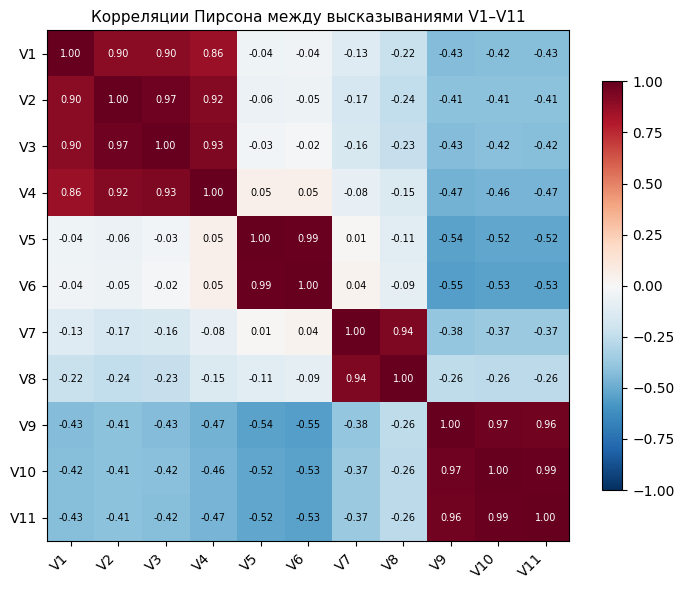

In [9]:
corr = raw.corr()
fig, ax = plt.subplots(figsize=(7.2, 6))
im = heatmap(ax, corr.values, VARS, VARS, cmap="RdBu_r", vmin=-1, vmax=1, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Корреляции Пирсона между высказываниями V1–V11")
save_show(fig, "corr")

**Блочная структура данных:**

Анализ корреляционной матрицы демонстрирует деление переменных на четыре обособленных блока с высокой внутригрупповой связностью (коэффициент корреляции $|\mathbf{r}| \approx 0,86–0,99$):

| Блок | Переменные | Содержательная интерпретация |
| :--- | :--- | :--- |
| **Освежение** | V1–V4 | Свежесть дыхания, гигиена полости рта, устранение неприятного привкуса, уверенность |
| **Сладкое** | V5–V6 | Замещение кондитерских изделий / сладкого |
| **Концентрация** | V7–V8 | Повышение концентрации внимания, функциональная пауза |
| **Здоровье** | V9–V11 | Облегчение боли в горле, устранение заложенности носа, улучшение общего самочувствия |

Межблочные корреляционные связи близки к нулю или имеют отрицательные значения, что свидетельствует о взаимоисключающем характере мотивационных выборов: респондент, ориентированный на реализацию одной цели, как правило, не выбирает остальные. Данная особенность предвосхищает четкую сегментацию выборки по доминирующей целевой установке. Сформированные блоки используются в дальнейшем **исключительно на этапе качественной интерпретации**, но не на этапе кластеризации.

In [10]:
BLOCKS = {
    "Свежесть":  ["V1", "V2", "V3", "V4"],
    "Сладкое":   ["V5", "V6"],
    "Фокус":     ["V7", "V8"],
    "Здоровье":  ["V9", "V10", "V11"],
}
SEG_ORDER = list(BLOCKS)

X = raw.to_numpy(dtype=float)
N = len(X)
print("X:", X.shape)

X: (338, 11)


## A.2. Выбор числа кластеров

Для определения оптимального числа кластеров $k$ привлекаются пять независимых критериев: метод локтя (анализ внутрикластерной суммы квадратов / инерции), средний коэффициент силуэта, индексы Калински — Харабаса и Дэвиса — Болдина, а также **$Gap$-статистика** (Tibshirani et al., 2001). Дополнительно проводится верификация **устойчивости** полученной структуры методом повторной выборки.

In [11]:
K_RANGE = list(range(2, 11))
Z = linkage(X, "ward")

In [12]:
K_FULL = list(range(1, 11))
km_models = {k: fit_kmeans(X, k) for k in K_FULL}
inertia = pd.Series({k: m.inertia_ for k, m in km_models.items()}, name="inertia")

km_tab = pd.DataFrame({k: internal_scores(X, km_models[k].labels_) for k in K_RANGE}).T
km_tab.insert(0, "inertia", inertia.loc[K_RANGE])
km_tab.index.name = "k"
display(km_tab)

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,1823.304,0.455,246.334,0.930
3,879.717,0.614,434.178,0.784
4,423.144,0.727,720.103,0.433
5,326.246,0.702,723.115,0.634
6,286.585,0.724,665.761,0.632
7,250.528,0.726,640.678,0.624
8,222.213,0.634,623.263,0.849
9,196.023,0.658,621.839,0.699
10,174.279,0.670,624.366,0.802


In [13]:
gap_tab = gap_statistic(X, K_FULL, B=50)
rule = [k for k in K_FULL[:-1] if gap_tab.gap[k] >= gap_tab.gap[k + 1] - gap_tab.s[k + 1]]
display(gap_tab.T)
print("k по правилу 1-SE:", rule[0] if rule else "правило не сработало на диапазоне k = 1..10")
print("Приращения gap при k -> k+1:", gap_tab.gap.diff().round(3).dropna().to_dict())

,1,2,3,4,5,6,7,8,9,10
gap,0.161,0.389,0.948,1.556,1.724,1.753,1.755,1.888,1.972,1.991
s,0.024,0.023,0.022,0.022,0.017,0.022,0.017,0.019,0.019,0.017


k по правилу 1-SE: 6
Приращения gap при k -> k+1: {2: 0.228, 3: 0.559, 4: 0.609, 5: 0.168, 6: 0.029, 7: 0.001, 8: 0.134, 9: 0.084, 10: 0.018}


In [14]:
stab_rows = []
for k in range(2, 9):
    m_km = subsample_stability(X, k, "kmeans", km_models[k].labels_)
    m_wd = subsample_stability(X, k, "ward", fcluster(Z, k, "maxclust"))
    stab_rows.append({"k": k, "k-means: ARI": m_km[0], "k-means: SD": m_km[1], "Ward: ARI": m_wd[0], "Ward: SD": m_wd[1]})
stab = pd.DataFrame(stab_rows).set_index("k")
display(stab)

,k-means: ARI,k-means: SD,Ward: ARI,Ward: SD
k,,,,
2,0.981,0.130,0.990,0.095
3,1.000,0.000,1.000,0.000
4,1.000,0.000,1.000,0.000
5,0.998,0.003,0.993,0.011
6,0.966,0.034,0.991,0.019
7,0.962,0.057,0.992,0.012
8,0.860,0.052,0.935,0.071


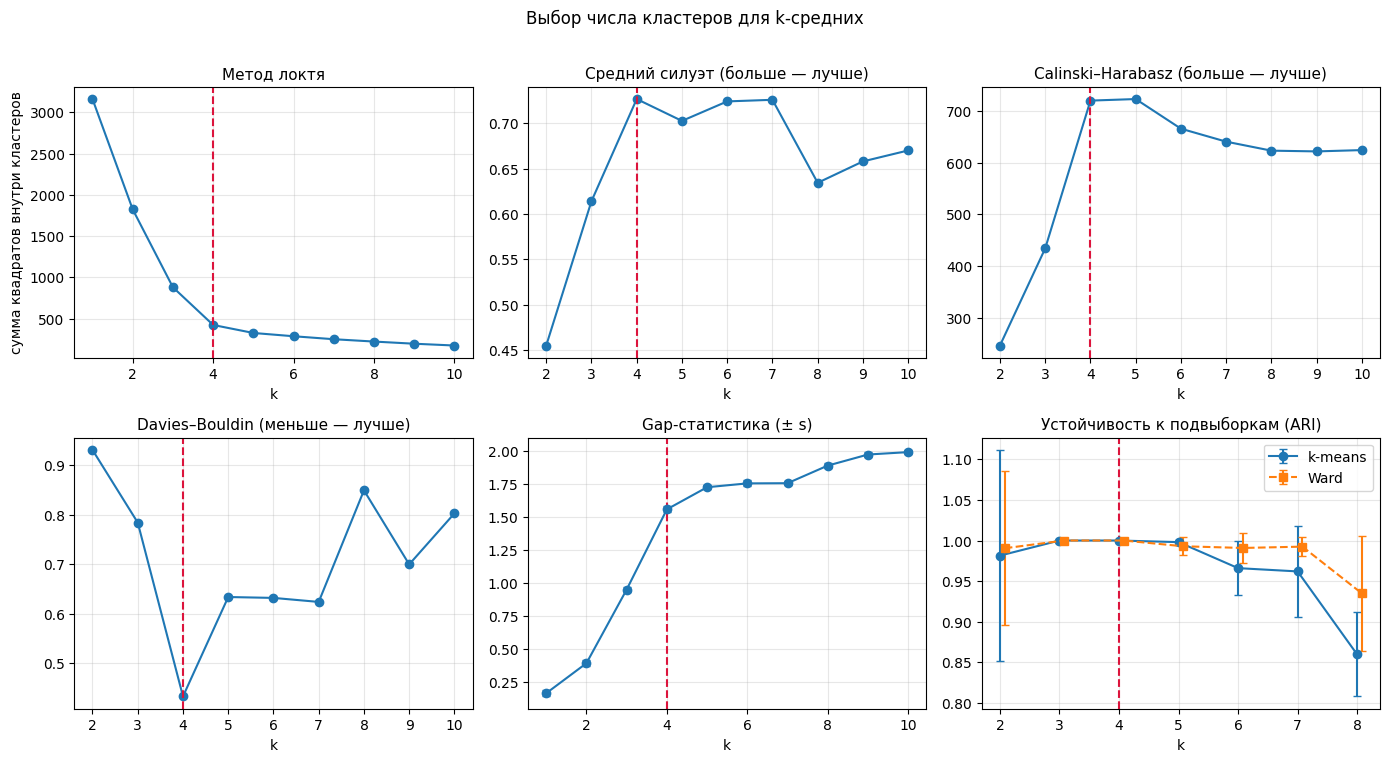

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
ax = axes[0, 0]; ax.plot(K_FULL, inertia.values, "o-"); ax.axvline(4, color="crimson", ls="--")
ax.set(title="Метод локтя", xlabel="k", ylabel="сумма квадратов внутри кластеров")
ax = axes[0, 1]; ax.plot(K_RANGE, km_tab.silhouette, "o-"); ax.axvline(4, color="crimson", ls="--")
ax.set(title="Средний силуэт (больше — лучше)", xlabel="k")
ax = axes[0, 2]; ax.plot(K_RANGE, km_tab.calinski_harabasz, "o-"); ax.axvline(4, color="crimson", ls="--")
ax.set(title="Calinski–Harabasz (больше — лучше)", xlabel="k")
ax = axes[1, 0]; ax.plot(K_RANGE, km_tab.davies_bouldin, "o-"); ax.axvline(4, color="crimson", ls="--")
ax.set(title="Davies–Bouldin (меньше — лучше)", xlabel="k")
ax = axes[1, 1]; ax.errorbar(K_FULL, gap_tab.gap, yerr=gap_tab.s, fmt="o-", capsize=3); ax.axvline(4, color="crimson", ls="--")
ax.set(title="Gap-статистика (± s)", xlabel="k")
ax = axes[1, 2]
ax.errorbar(stab.index, stab["k-means: ARI"], yerr=stab["k-means: SD"], fmt="o-", capsize=3, label="k-means")
ax.errorbar(stab.index + 0.08, stab["Ward: ARI"], yerr=stab["Ward: SD"], fmt="s--", capsize=3, label="Ward")
ax.axvline(4, color="crimson", ls="--"); ax.legend(); ax.set(title="Устойчивость к подвыборкам (ARI)", xlabel="k")
fig.suptitle("Выбор числа кластеров для k-средних", y=1.01)
save_show(fig, "kmeans_choice")

**Вывод ЛР 2 часть А.**

* **Метод локтя (анализ инерции):** Суммарная внутрикластерная дисперсия резко сокращается при последовательном увеличении числа кластеров от 1 до 4 ($\approx 3160 \rightarrow 1823 \rightarrow 880 \rightarrow 423$), после чего темп убывания существенно замедляется, достигая $326$ при $k = 5$. Таким образом, четко выраженный излом функции инерции зафиксирован в точке $k = 4$.
* **Внутренние критерии (силуэт / CH / DB):** При $k = 4$ средний коэффициент силуэта достигает абсолютного максимума ($0{,}727$), а индекс Дэвиса — Болдина принимает минимальное значение ($0{,}433$). Индекс Калински — Харабаса ($720$) в этой точке практически равен своему пиковому значению при $k = 5$ ($723$; расхождение не превышает $0{,}4\,\%$).
* **Анализ $Gap$-статистики:** Классическое правило *1-SE* на рассматриваемом интервале оказывается неэффективным: наблюдается монотонный рост кривой $Gap$, обусловленный дискретным характером данных и наличием множественных дублирующихся профилей, для которых равномерное нулевое распределение некорректно. Тем не менее прирост значений $Gap$-статистики резко затухает именно после $k = 4$, что позволяет использовать данный показатель в качестве вспомогательного подтверждающего индикатора.
* **Оценка устойчивости:** При $k = 3$ и $k = 4$ результаты разбиения обладают абсолютной воспроизводимостью на подвыборках ($ARI = 1{,}00$; $SD = 0$). При $k = 5$ уровень устойчивости остаётся крайне высоким ($\approx 0{,}998$), а начиная с $k \ge 6$ закономерно снижается (для метода $k$-средних: $\approx 0{,}96$ при $k = 6–7$ и $\approx 0{,}86$ при $k = 8$). Оценка устойчивости исключает завышенные значения $k$, а окончательный выбор в пользу $k = 4$ против $k = 5$ обеспечивается комплексом внутренних индексов.

**Итоговое решение:**

Совокупный анализ всех критериев однозначно указывает на оптимальность разбиения при **$k = 4$**. Примечательно, что при $k \in \{2, 3, 4\}$ метод Уорда и алгоритм $k$-средних формируют **полностью идентичные** кластерные структуры ($ARI = 1{,}00$).

## A.3. Итоговое разбиение и проверка робастности

In [16]:
K_FINAL = 4
km = fit_kmeans(X, K_FINAL, n_init=100)
labels_km = km.labels_
labels_ward = fcluster(Z, K_FINAL, "maxclust") - 1

print("Размеры кластеров k-means:", np.bincount(labels_km).tolist())
print("ARI(k-means, Ward) при k = 4 :", round(adjusted_rand_score(labels_km, labels_ward), 4))

Xs = StandardScaler().fit_transform(X)
lab_std = fit_kmeans(Xs, K_FINAL, n_init=100).labels_
lab_seed = fit_kmeans(X, K_FINAL, n_init=100, seed=7).labels_
print("ARI(исходная шкала и стандартизация) :", round(adjusted_rand_score(labels_km, lab_std), 4))
print("ARI(зерно 42 и зерно 7)              :", round(adjusted_rand_score(labels_km, lab_seed), 4))

Размеры кластеров k-means: [108, 61, 110, 59]
ARI(k-means, Ward) при k = 4 : 1.0
ARI(исходная шкала и стандартизация) : 1.0
ARI(зерно 42 и зерно 7)              : 1.0


## A.4. Интерпретация сегментов

Средний силуэт: 0.727;  респондентов с отрицательным силуэтом: 0 из 338


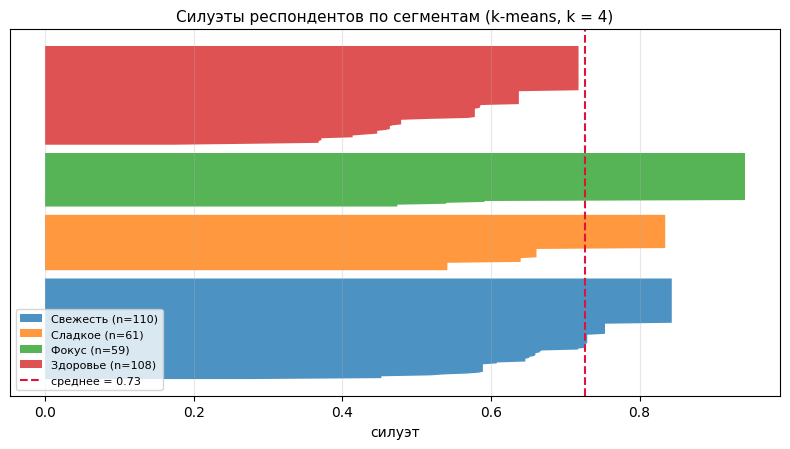

In [17]:
sil_i = silhouette_samples(X, labels_km)
print(f"Средний силуэт: {sil_i.mean():.3f};  респондентов с отрицательным силуэтом: {(sil_i < 0).sum()} из {N}")

def name_clusters(labels, X=X, X_ref=X):
    names = {}
    for c in sorted(set(labels) - {-1}):
        centre = X[labels == c].mean(0)
        score = {b: np.mean([centre[VARS.index(v)] - X_ref[:, VARS.index(v)].mean() for v in vs]) for b, vs in BLOCKS.items()}
        names[c] = max(score, key=score.get)
    assert len(set(names.values())) == len(names), "два кластера получили одно имя — проверить разбиение"
    if -1 in labels:
        names[-1] = "Шум"
    return names

name_km = name_clusters(labels_km)
seg_km = pd.Series(labels_km).map(name_km)

fig, ax = plt.subplots(figsize=(8, 4.6))
y0 = 0
for seg in SEG_ORDER:
    v = np.sort(sil_i[(seg_km == seg).to_numpy()])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.8, label=f"{seg} (n={len(v)})")
    y0 += len(v) + 8
ax.axvline(sil_i.mean(), color="crimson", ls="--", label=f"среднее = {sil_i.mean():.2f}")
ax.set(title="Силуэты респондентов по сегментам (k-means, k = 4)", xlabel="силуэт", yticks=[])
ax.legend(loc="lower left", fontsize=8)
save_show(fig, "silhouette")

### Профили сегментов

In [18]:
res = raw.copy()
res["сегмент"] = pd.Categorical(seg_km, categories=SEG_ORDER, ordered=True)

size = res["сегмент"].value_counts().reindex(SEG_ORDER)
profile = res.groupby("сегмент", observed=True)[VARS].mean().reindex(SEG_ORDER)
print("Размеры сегментов:")
display(pd.DataFrame({"n": size, "доля": size / N}).T)
print("Средние оценки по высказываниям:")
display(pd.concat([profile, raw.mean().rename("вся выборка").to_frame().T]))

top2 = res.groupby("сегмент", observed=True)[VARS].agg(lambda s: (s >= 4).mean()).reindex(SEG_ORDER)
print("Доля респондентов, согласных с высказыванием:")
display(top2)

Размеры сегментов:


сегмент,Свежесть,Сладкое,Фокус,Здоровье
n,110.000,61.00,59.000,108.00
доля,0.325,0.18,0.175,0.32


Средние оценки по высказываниям:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Свежесть,4.845,4.800,4.836,4.682,3.036,3.036,3.000,2.991,3.073,3.045,3.045
Сладкое,3.000,3.000,3.000,3.000,4.852,4.852,3.000,2.918,2.754,2.754,2.754
Фокус,3.000,2.966,2.966,2.915,2.915,2.949,4.915,4.915,3.000,3.000,3.000
Здоровье,2.824,2.833,2.769,2.620,2.611,2.583,2.750,2.917,4.954,4.815,4.861
вся выборка,3.544,3.527,3.518,3.411,3.207,3.204,3.254,3.290,3.604,3.550,3.565


Доля респондентов, согласных с высказыванием:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
сегмент,,,,,,,,,,,
Свежесть,1.0,1.000,1.000,1.000,0.036,0.036,0.000,0.027,0.073,0.045,0.045
Сладкое,0.0,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
Фокус,0.0,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000
Здоровье,0.0,0.037,0.037,0.037,0.000,0.000,0.065,0.065,1.000,1.000,1.000


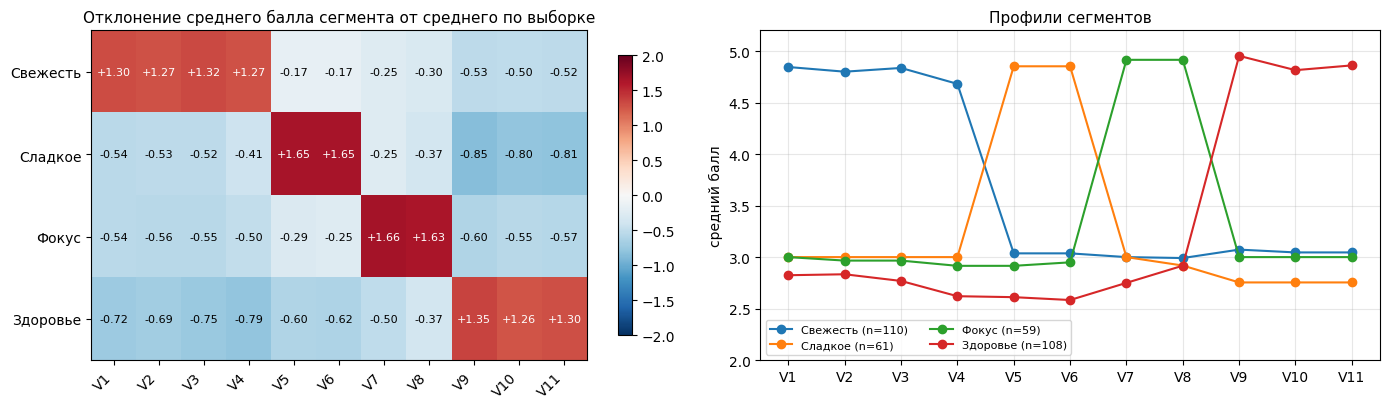

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
diff = profile - raw.mean()
im = heatmap(axes[0], diff.values, VARS, SEG_ORDER, fmt="{:+.2f}", cmap="RdBu_r", vmin=-2, vmax=2)
fig.colorbar(im, ax=axes[0], shrink=0.85)
axes[0].set_title("Отклонение среднего балла сегмента от среднего по выборке")

colors = plt.cm.tab10.colors
for i, seg in enumerate(SEG_ORDER):
    axes[1].plot(VARS, profile.loc[seg], "o-", color=colors[i], label=f"{seg} (n={size[seg]})")
axes[1].set(title="Профили сегментов", ylabel="средний балл", ylim=(2, 5.2))
axes[1].legend(fontsize=8, ncol=2)
save_show(fig, "profiles")

### 7.2. Проекция на главные компоненты

Метод главных компонент применяется исключительно в целях визуализации данных и верификации выделенной блочной структуры, в то время как процедура кластеризации выполнялась непосредственно на пространстве исходных признаков.

Для обеспечения наглядности и предотвращения наложения совпадающих наблюдений на графике к координатам был добавлен незначительный случайный шум, затрагивающий исключительно графическое представление.

Доля объяснённой дисперсии: [0.499, 0.281, 0.151, 0.036] | накопленная: [0.499, 0.78, 0.931, 0.967]


,PC1,PC2,PC3,PC4
V1,0.360,-0.280,0.044,0.023
V2,0.366,-0.308,0.035,0.098
V3,0.385,-0.308,0.029,0.153
V4,0.393,-0.251,0.041,0.339
V5,0.141,0.344,-0.455,0.375
V6,0.146,0.352,-0.442,0.382
V7,0.040,0.305,0.528,0.364
V8,-0.007,0.269,0.552,0.318
V9,-0.372,-0.302,-0.047,0.279
V10,-0.353,-0.290,-0.053,0.358


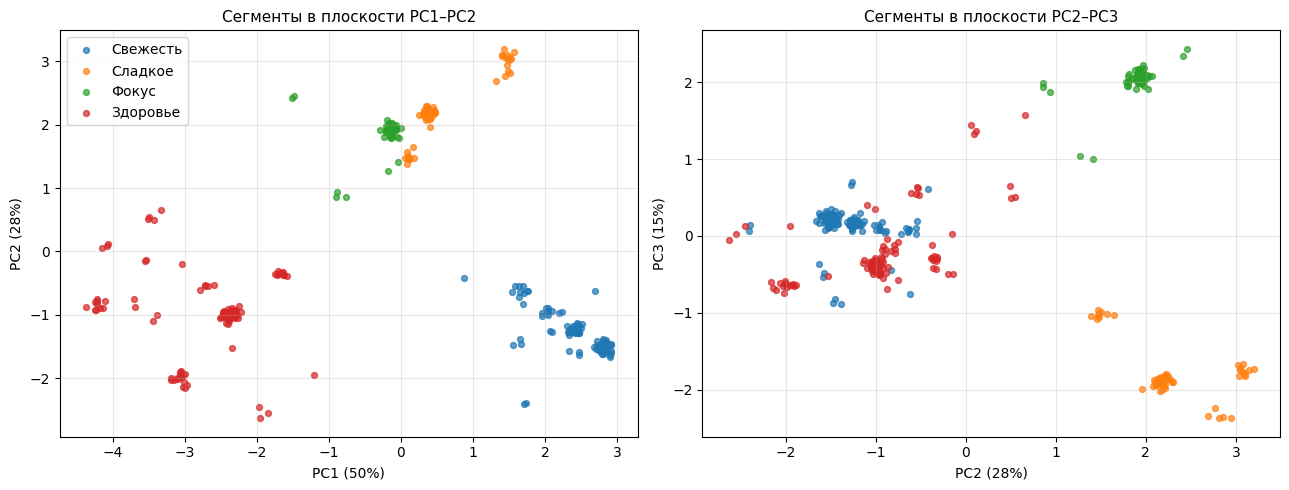

In [20]:
pca = PCA(n_components=4, random_state=SEED).fit(X)
P = pca.transform(X)
load = pd.DataFrame(pca.components_.T, index=VARS, columns=[f"PC{i+1}" for i in range(4)])
print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_.round(3).tolist(),
      "| накопленная:", pca.explained_variance_ratio_.cumsum().round(3).tolist())
display(load)

rng = np.random.default_rng(SEED)
J = P + rng.normal(0, 0.06, P.shape)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (a, b), ax in zip([(0, 1), (1, 2)], axes):
    for i, seg in enumerate(SEG_ORDER):
        msk = (seg_km == seg).to_numpy()
        ax.scatter(J[msk, a], J[msk, b], s=18, alpha=0.7, color=colors[i], label=seg)
    ax.set(xlabel=f"PC{a+1} ({pca.explained_variance_ratio_[a]:.0%})", ylabel=f"PC{b+1} ({pca.explained_variance_ratio_[b]:.0%})")
axes[0].legend(); axes[0].set_title("Сегменты в плоскости PC1–PC2"); axes[1].set_title("Сегменты в плоскости PC2–PC3")
save_show(fig, "pca")

Первые три главные компоненты кумулятивно описывают около 93 % общей дисперсии, а четыре — порядка 97 %. Фактическая размерность пространства данных составляет три, что согласуется с наличием четырех центроидов кластеров. На плоскостях проекций выделенные сегменты формируют четыре компактные области, что визуально подтверждает высокую чёткость и обособленность полученного разбиения.

### 7.3. Содержательная интерпретация сегментов

### Содержательная интерпретация

In [21]:
for seg in SEG_ORDER:
    dom = profile.loc[seg].sort_values(ascending=False)
    top = dom[dom >= 4].index.tolist()
    low = profile.loc[seg][profile.loc[seg] < 3].index.tolist()
    print(f"{seg:<9} n={size[seg]:>3} ({size[seg]/N:.1%}) | высокие (≥4): {', '.join(top)} | ниже нейтрального 3: {', '.join(low) if low else '—'}")

Свежесть  n=110 (32.5%) | высокие (≥4): V1, V3, V2, V4 | ниже нейтрального 3: V8
Сладкое   n= 61 (18.0%) | высокие (≥4): V5, V6 | ниже нейтрального 3: V8, V9, V10, V11
Фокус     n= 59 (17.5%) | высокие (≥4): V7, V8 | ниже нейтрального 3: V2, V3, V4, V5, V6
Здоровье  n=108 (32.0%) | высокие (≥4): V9, V11, V10 | ниже нейтрального 3: V1, V2, V3, V4, V5, V6, V7, V8


В результате проведенной сегментации выделены четыре устойчивые группы потребителей, полностью удовлетворяющие базовым маркетинговым критериям: интерпретируемости (каждая группа имеет четкую доминирующую цель), измеримости (профиль однозначно восстанавливается по 2–4 индикаторам) и достаточной емкости (наименьший сегмент составляет $17{,}5\,\%$ совокупности).

| Сегмент | Доля | Доминирующая цель потребления | Интерпретация и стратегические рекомендации |
| :--- | :--- | :--- | :--- |
| **«Свежесть»**<br>($V_1–V_4$) | $\approx 32{,}5\,\%$ | Освежение дыхания и полости рта, устранение неприятного привкуса, повышение уверенности в коммуникации | Потребление носит функционально-гигиенический характер. Ключевые требования: выраженный мятный профиль, пролонгированный освежающий эффект, коммуникация через атрибут уверенности в социальных контактах. |
| **«Здоровье»**<br>($V_9–V_{11}$) | $\approx 32{,}0\,\%$ | Облегчение болевых ощущений в горле, купирование заложенности носа, улучшение общего состояния | Функциональное (лечебно-профилактическое) потребление с вероятным сезонным всплеском. Приоритетные факторы: натуральный состав (лекарственные травы, ментол, эвкалипт), дистрибуция через аптечный канал, позиционирование в парадигме заботы о здоровье. |
| **«Сладкое»**<br>($V_5–V_6$) | $\approx 18{,}0\,\%$ | Замещение кондитерских изделий, удовлетворение потребности в сладком | Леденец выступает в качестве альтернативы десерту. Критичные параметры: вкусовые характеристики, разнообразие ассортиментной линейки, ценовой фактор, ориентация на импульсный спрос (размещение в прикассовых зонах). |
| **«Фокус»**<br>($V_7–V_8$) | $\approx 17{,}5\,\%$ | Стимуляция концентрации внимания, организация когнитивной паузы | Использование продукта как инструмента в профессиональной деятельности или учебе. Перспективные направления: таргетинг на офисных сотрудников и студенческую аудиторию, акцент на позиционировании «продуктивность и фокус». |

**Анализ профилей мотивации:**

Полученные сегменты демонстрируют специфические паттерны восприятия альтернативных целевых установок. В группах «Здоровье», «Сладкое» и «Фокус» средние оценки по нецелевым направлениям падают ниже нейтрального порога в 3 балла (в сегменте «Здоровье» — вплоть до $0{,}4$ балла), что свидетельствует об осознанном отвержении респондентами прочих мотиваций и высокой степени концентрации на доминирующей цели. Исключением выступает сегмент «Свежесть», средние оценки которого по остальным целям удерживаются вблизи нейтрального уровня.

### Вложенная структура: разбиение на 6 кластеров

In [22]:
km6 = fit_kmeans(X, 6, n_init=100)
ct = pd.crosstab(pd.Series(km6.labels_, name="кластер k=6"), seg_km.rename("сегмент k=4"))[SEG_ORDER]
display(ct)

prof6 = pd.DataFrame(X, columns=VARS).groupby(km6.labels_).mean()
prof6.insert(0, "n", np.bincount(km6.labels_))
prof6["родитель (k=4)"] = ct.idxmax(axis=1)
prof6 = prof6.sort_values(["родитель (k=4)", "n"], ascending=[True, False])
display(prof6)

сегмент k=4,Свежесть,Сладкое,Фокус,Здоровье
кластер k=6,,,,
0,0,0,59,0
1,110,0,0,0
2,0,0,0,29
3,0,61,0,0
4,0,0,0,63
5,0,0,0,16


,n,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,родитель (k=4)
4,63,2.937,3.063,3.063,3.063,2.937,2.937,2.937,3.000,4.937,4.825,4.889,Здоровье
2,29,2.483,2.241,2.000,2.000,2.241,2.138,2.759,3.241,4.966,4.724,4.759,Здоровье
5,16,3.000,3.000,3.000,2.000,2.000,2.000,2.000,2.000,5.000,4.938,4.938,Здоровье
1,110,4.845,4.800,4.836,4.682,3.036,3.036,3.000,2.991,3.073,3.045,3.045,Свежесть
3,61,3.000,3.000,3.000,3.000,4.852,4.852,3.000,2.918,2.754,2.754,2.754,Сладкое
0,59,3.000,2.966,2.966,2.915,2.915,2.949,4.915,4.915,3.000,3.000,3.000,Фокус


**Анализ детализированной структуры при $k = 6$:**

Разбиение массива данных на шесть кластеров **полностью сохраняет** в неизменном виде ключевые сегменты «Свежесть», «Сладкое» и «Фокус», в то время как обширная группа «Здоровье» дробится на три самостоятельные подкатегории:
* **«Чистое здоровье»** ($63$ респондента, $18{,}6\,\%$ от выборки) — группа с ярко выраженной функциональной направленностью, где сопутствующие потребительские цели находятся на нейтральном уровне $\approx 3$ баллов.
* **«Здоровье с отказом от свежести и сладкого»** ($29$ респондентов, $8{,}6\,\%$), характеризующаяся снижением оценок по переменным $V1–V6$ до уровня $2{,}0–2{,}5$ баллов.
* **«Здоровье с жестким отказом практически от всех прочих мотивов»** ($16$ респондентов, $4{,}7\,\%$), для которой показатели $V4–V8$ падают до минимального порога в $2$ балла.

Две последние малочисленные подгруппы различаются главным образом глубиной отрицания альтернативных потребительских мотивов. Ввиду ограниченного объема они не отвечают требованию достаточной рыночной емкости для использования в качестве самостоятельных макросегментов, однако представляют высокую ценность для микросегментации и глубокой кастомизации маркетинговых коммуникаций внутри базовой аудитории «Здоровье».

### Выводы по части A

1. **Обоснование числа кластеров ($k = 4$):** Значения инерции демонстрируют резкое сокращение при переходе от 1 до 4 ($\approx 3160 \rightarrow 1823 \rightarrow 880 \rightarrow 423$) с последующим плавным снижением до $326$ при $k = 5$. При $k = 4$ достигаются максимальный средний коэффициент силуэта $0{,}727$ и минимальный индекс Дэвиса — Болдина $0{,}433$, в то время как индекс Калински — Харабаса $720{,}1$ практически совпадает со своим пиком при $k = 5$ равном $723{,}1$; расхождение составляет $0{,}4\,\%$. Приросты $Gap$-статистики резко затухают после $k = 4$ ($+0{,}61$ при переходе $3 \rightarrow 4$, далее $+0{,}17$ и ниже); классическое правило *1-SE* в данном случае не срабатывает из-за дискретной природы данных и множественных дублирующихся профилей, снижающих корректность равномерной нулевой модели. Устойчивость разбиения на подвыборках абсолютна при $k = 3$ и $k = 4$ $ARI = 1{,}00$ и закономерно снижается при $k \ge 6$.

2. **Робастность и инвариантность итогового разбиения:** Финальная кластерная структура $k = 4$, размеры групп составляют $108$, $61$, $110$ и $59$ наблюдений, проявляет полную инвариантность к процедуре стандартизации признаков, выбору зерна инициализации псевдослучайных чисел и применяемому алгоритму кластеризации. Коэффициент $ARI = 1{,}00$ при сопоставлении с результатами метода Уорда.

3. **Содержательная интерпретация:** Выделенные сегменты по доминирующей потребительской цели распределяются следующим образом: «Свежесть» ($110$ респондентов, $32{,}5\,\%$), «Здоровье» ($108$ респондентов, $32{,}0\,\%$), «Сладкое» ($61$ респондент, $18{,}0\,\%$) и «Фокус» ($59$ респондентов, $17{,}5\,\%$). Среднее значение коэффициента силуэта равно $0{,}727$ при полном отсутствии отрицательных показателей. При детализации структуры до $k = 6$ сегмент «Здоровье» разделяется на три подгруппы ($63$, $29$ и $16$ респондентов), дифференцируемые по степени отказа от альтернативных мотиваций.

4. **Методические ограничения:** Анализируемый массив данных ограничен $45$ уникальными профилями ответов, а эффективный диапазон измерительной шкалы фактически находится в пределах от 2 до 5, что обусловлено учебным характером датасета. Кроме того, исходная порядковая шкала в рамках применяемого математического аппарата условно трактуется как интервальная.

# Часть B. Данные «Цифры»

In [23]:
FIG_PREFIX = "digits"
DATA_PATH = DIGITS_PATH

## B.1. Описание данных и разведочный анализ

In [24]:
raw = pd.read_csv(DATA_PATH, sep=";", dtype=str).apply(lambda s: s.str.strip())
SEG = list("BCDEFGH")
assert (raw[SEG].to_numpy() == raw[[s + "2" for s in SEG]].to_numpy()).all() and (raw["A"] == raw["A2"]).all(), "дубли столбцов не совпадают"
print("Значения признаков:", sorted(set(raw[SEG].to_numpy().ravel())), "| значения A:", sorted(raw["A"].str.lower().unique()))

X = (raw[SEG] == "ONE").astype(int).to_numpy()
y = raw["A"].str.lower().to_numpy()
N = len(X)
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
DIGIT_NUM = {d: i for i, d in enumerate(DIGITS)}
print(f"Объектов: {N}; признаков: {X.shape[1]}; уникальных комбинаций сегментов: {len(np.unique(X, axis=0))} из 128 возможных")

Значения признаков: ['ONE', 'ZERO'] | значения A: ['eight', 'five', 'four', 'nine', 'one', 'seven', 'six', 'three', 'two', 'zero']
Объектов: 500; признаков: 7; уникальных комбинаций сегментов: 75 из 128 возможных


### Проверка корректности кодирования и уровня шума

Эталонная матрица начертаний цифр для семисегментного индикатора строится на основе следующей топологии элементов: `B` — верхний горизонтальный, `C` — верхний левый вертикальный, `D` — верхний правый вертикальный, `E` — средний горизонтальный, `F` — нижний левый вертикальный, `G` — нижний правый вертикальный, `H` — нижний горизонтальный.

Данные эталонные конфигурации применяются **исключительно** для верификации схемы кодирования и количественной оценки уровня искажений; процедура кластеризации выполняется без их непосредственного использования.

In [25]:
CANON = {"zero":  [1, 1, 1, 0, 1, 1, 1], "one":   [0, 0, 1, 0, 0, 1, 0], "two":   [1, 0, 1, 1, 1, 0, 1],
         "three": [1, 0, 1, 1, 0, 1, 1], "four":  [0, 1, 1, 1, 0, 1, 0], "five":  [1, 1, 0, 1, 0, 1, 1],
         "six":   [1, 1, 0, 1, 1, 1, 1], "seven": [1, 0, 1, 0, 0, 1, 0], "eight": [1] * 7, "nine":  [1, 1, 1, 1, 0, 1, 1]}
CANON["seven"] = [1, 0, 1, 0, 0, 1, 0]
Cmat = np.array([CANON[d] for d in y])

print(f"Согласие с эталонами при ONE = «горит»: {(X == Cmat).mean():.3f}")
print(f"Согласие с эталонами при инверсии: {(X != Cmat).mean():.3f}")
print(f"Доля искажённых сегментов: {(X != Cmat).mean():.3f}")
print(f"Доля цифр, записанных без единой ошибки: {(X == Cmat).all(1).mean():.3f}")
nearest = np.array([min(CANON, key=lambda k: (x != np.array(CANON[k])).sum()) for x in X])
print(f"Потолок для безэталонной кластеризации: {(nearest == y).mean():.3f}")

freq = pd.Series(y).value_counts().reindex(DIGITS)
prof_true = pd.DataFrame(X, columns=SEG).groupby(y).mean().reindex(DIGITS)
print("\nЧисло объектов по цифрам:", freq.to_dict())
display(prof_true.round(2))

Согласие с эталонами при ONE = «горит»: 0.901
Согласие с эталонами при инверсии: 0.099
Доля искажённых сегментов: 0.099
Доля цифр, записанных без единой ошибки: 0.488
Потолок для безэталонной кластеризации: 0.746

Число объектов по цифрам: {'zero': 42, 'one': 43, 'two': 43, 'three': 55, 'four': 52, 'five': 54, 'six': 50, 'seven': 48, 'eight': 58, 'nine': 55}


,B,C,D,E,F,G,H
zero,0.90,0.86,0.98,0.12,0.90,0.93,0.88
one,0.09,0.07,0.93,0.09,0.21,0.88,0.16
two,0.88,0.09,0.81,0.93,0.88,0.02,0.93
three,0.91,0.15,0.91,0.93,0.15,0.95,0.85
four,0.08,0.87,0.88,0.98,0.15,0.88,0.12
five,0.91,0.98,0.15,0.98,0.11,0.93,0.89
six,0.90,0.88,0.02,0.88,0.94,0.90,0.88
seven,0.88,0.15,0.88,0.12,0.08,0.92,0.08
eight,0.91,0.95,0.90,0.97,0.83,0.88,0.88
nine,0.95,0.80,0.87,0.96,0.07,0.91,0.91


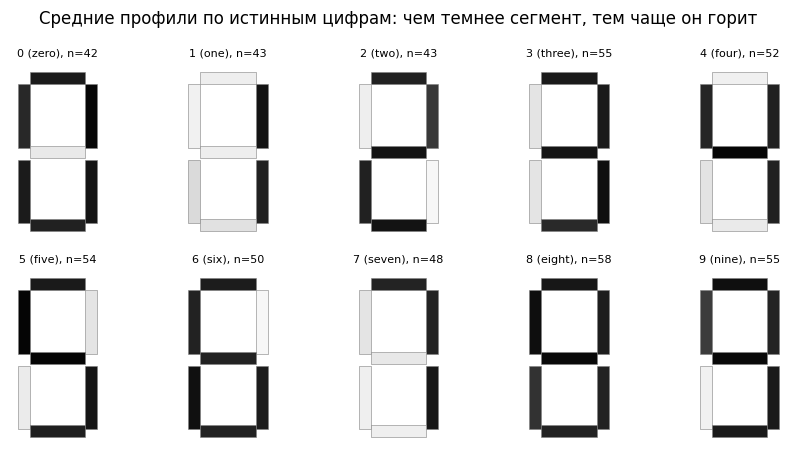

In [26]:
def draw_digit(ax, probs, title=None, fs=8):
    geom = {"B": (0.15, 1.85, 0.7, 0.15), "C": (0.0, 1.05, 0.15, 0.8), "D": (0.85, 1.05, 0.15, 0.8),
            "E": (0.15, 0.925, 0.7, 0.15), "F": (0.0, 0.1, 0.15, 0.8), "G": (0.85, 0.1, 0.15, 0.8), "H": (0.15, 0.0, 0.7, 0.15)}
    for s, pr in zip(SEG, probs):
        x0, y0, w, h = geom[s]
        ax.add_patch(plt.Rectangle((x0, y0), w, h, facecolor=plt.cm.Greys(0.05 + 0.95 * float(pr)), edgecolor="grey", lw=0.4))
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.1, 2.1); ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title, fontsize=fs)

fig, axes = plt.subplots(2, 5, figsize=(9, 4.6))
for ax, d in zip(axes.ravel(), DIGITS):
    draw_digit(ax, prof_true.loc[d].to_numpy(), f"{DIGIT_NUM[d]} ({d}), n={freq[d]}")
fig.suptitle("Средние профили по истинным цифрам: чем темнее сегмент, тем чаще он горит")
save_show(fig, "true_profiles")

**Наблюдения:**

Эмпирические профили каждой цифры демонстрируют в целом высокое соответствие эталонным конфигурациям, однако около $10\,\%$ индивидуальных сегментов содержат искажения, а полностью безошибочная запись характерна лишь примерно для половины исследуемых знаков.

Даже гипотетический идеальный классификатор, функционирующий по критерию ближайшего эталона с априорным знанием всех десяти базовых начертаний, способен обеспечить точность не выше $\approx 75\,\%$. В связи с этим формирование идеально «чистых» кластеров методологически недостижимо: часть цифровых знаков обладает высокой степенью структурного пересечения, например, символы `1` и `7` различаются всего одним элементом.

Данное обстоятельство определяет объективный верхний предел эффективности и задает реалистичный уровень ожиданий от процедур безэталонной кластеризации.

## B.2. Выбор числа кластеров

В дополнение к базовому комплексу диагностических показателей (анализ инерции, коэффициент силуэта, индексы Калински — Харабаса и Дэвиса — Болдина, а также оценка устойчивости) привлекаются два специализированных критерия, адаптированных к дихотомической структуре признакового пространства:

* **$Gap$-статистика с адаптированной нулевой моделью:** генерация референтных данных осуществляется на основе независимых бинарных признаков с сохранением эмпирических вероятностей проявления каждого отдельного сегмента.
* **Байесовский информационный критерий (BIC) для смеси бернуллиевских распределений:** применяется в рамках латентно-классового анализа (LCA) для формальной оценки оптимизации структуры вероятностной модели.

In [27]:
K_RANGE = list(range(2, 16))
Z = linkage(X, "ward")
hier_tab = pd.DataFrame({k: internal_scores(X, fcluster(Z, k, "maxclust"), metric="hamming") for k in K_RANGE}).T
hier_tab.index.name = "k"

In [28]:
K_FULL = list(range(1, 16))
km_models = {k: fit_kmeans(X, k, n_init=500) for k in K_FULL}
inertia = pd.Series({k: m.inertia_ for k, m in km_models.items()}, name="inertia")
km_tab = pd.DataFrame({k: internal_scores(X, km_models[k].labels_, metric="hamming") for k in K_RANGE}).T
km_tab.insert(0, "inertia", inertia.loc[K_RANGE]); km_tab.index.name = "k"
display(km_tab)

diag = []
for n_init in (10, 50, 100, 500):
    m = fit_kmeans(X, 10, n_init=n_init)
    dom_ = pd.crosstab(m.labels_, y).idxmax(axis=1)
    diag.append({"n_init": n_init, "инерция": m.inertia_, "различных доминирующих цифр": dom_.nunique()})
display(pd.DataFrame(diag).set_index("n_init").round(2))

def gap_binary(X, ks, B=50, seed=SEED):
    rng = np.random.default_rng(seed)
    pr = X.mean(0)
    logW = lambda M, k: np.log(KMeans(k, n_init=5, random_state=seed).fit(M).inertia_)
    obs = np.array([logW(X, k) for k in ks])
    ref = np.array([[logW((rng.random(X.shape) < pr).astype(float), k) for k in ks] for _ in range(B)])
    return pd.DataFrame({"gap": ref.mean(0) - obs, "s": ref.std(0) * np.sqrt(1 + 1 / B)}, index=list(ks))

gap_tab = gap_binary(X, K_FULL, B=50)
rule = [k for k in K_FULL[:-1] if gap_tab.gap[k] >= gap_tab.gap[k + 1] - gap_tab.s[k + 1]]
display(gap_tab.T.round(3))
print("k по правилу 1-SE:", rule[0] if rule else "правило не сработало")

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,555.241,0.381,143.691,1.713
3,463.371,0.350,135.186,1.650
4,405.158,0.358,126.620,1.473
5,355.732,0.389,125.136,1.372
6,310.603,0.419,128.778,1.216
7,278.987,0.464,128.546,1.177
8,252.426,0.472,128.924,1.113
9,231.197,0.482,128.552,1.125
10,210.911,0.506,130.241,1.063


,инерция,различных доминирующих цифр
n_init,,
10,220.79,9
50,220.79,9
100,214.01,10
500,210.91,10


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
gap,0.002,0.064,0.088,0.144,0.224,0.229,0.313,0.341,0.386,0.379,0.382,0.372,0.374,0.418,0.412
s,0.013,0.027,0.030,0.032,0.031,0.033,0.036,0.036,0.037,0.037,0.039,0.036,0.047,0.034,0.036


k по правилу 1-SE: 2


In [29]:
def bernoulli_mixture(X, k, seed, iters=300, tol=1e-7):
    n, p = X.shape
    init = KMeans(k, n_init=1, random_state=seed).fit(X).labels_
    R = np.eye(k)[init] * 0.8 + 0.2 / k
    ll_old = -np.inf
    for _ in range(iters):
        Nk = R.sum(0) + 1e-9
        pi = Nk / n
        th = np.clip((R.T @ X + 1e-3) / (Nk[:, None] + 2e-3), 1e-3, 1 - 1e-3)
        logp = np.log(pi)[None] + X @ np.log(th).T + (1 - X) @ np.log(1 - th).T
        m = logp.max(1, keepdims=True)
        ll = (m[:, 0] + np.log(np.exp(logp - m).sum(1))).sum()
        R = np.exp(logp - m); R /= R.sum(1, keepdims=True)
        if abs(ll - ll_old) < tol:
            break
        ll_old = ll
    return ll, th, pi, R

bic_rows, bmm_best = [], {}
for k in range(2, 15):
    best = max((bernoulli_mixture(X, k, s) for s in range(15)), key=lambda t: t[0])
    n_par = k * X.shape[1] + (k - 1)
    bic_rows.append({"k": k, "loglik": best[0], "BIC": -2 * best[0] + n_par * np.log(N)})
    bmm_best[k] = best
bic = pd.DataFrame(bic_rows).set_index("k")
display(bic.T.round(1))
print("Минимум BIC при k =", int(bic.BIC.idxmin()))

k,2,3,4,5,6,7,8,9,10,11,12,13,14
loglik,-1976.3,-1939.4,-1911.8,-1885.7,-1871.7,-1866.4,-1861.7,-1856.6,-1852.7,-1848.1,-1846.8,-1845.3,-1842.4
BIC,4045.8,4021.8,4016.3,4013.8,4035.4,4074.5,4114.9,4154.5,4196.4,4236.8,4284.1,4330.7,4374.6


Минимум BIC при k = 5


In [30]:
stab_rows = []
for k in range(2, 15):
    a = subsample_stability(X.astype(float), k, "kmeans", km_models[k].labels_, n_rep=50)
    b = subsample_stability(X.astype(float), k, "ward", fcluster(Z, k, "maxclust"), n_rep=50)
    stab_rows.append({"k": k, "k-means: ARI": a[0], "k-means: SD": a[1], "Ward: ARI": b[0], "Ward: SD": b[1]})
stab = pd.DataFrame(stab_rows).set_index("k")
display(stab.round(3))

,k-means: ARI,k-means: SD,Ward: ARI,Ward: SD
k,,,,
2,0.977,0.023,0.465,0.209
3,0.759,0.249,0.311,0.187
4,0.599,0.175,0.347,0.139
5,0.604,0.177,0.399,0.112
6,0.724,0.119,0.481,0.103
7,0.682,0.109,0.503,0.087
8,0.783,0.095,0.543,0.066
9,0.740,0.089,0.561,0.064
10,0.764,0.067,0.575,0.064


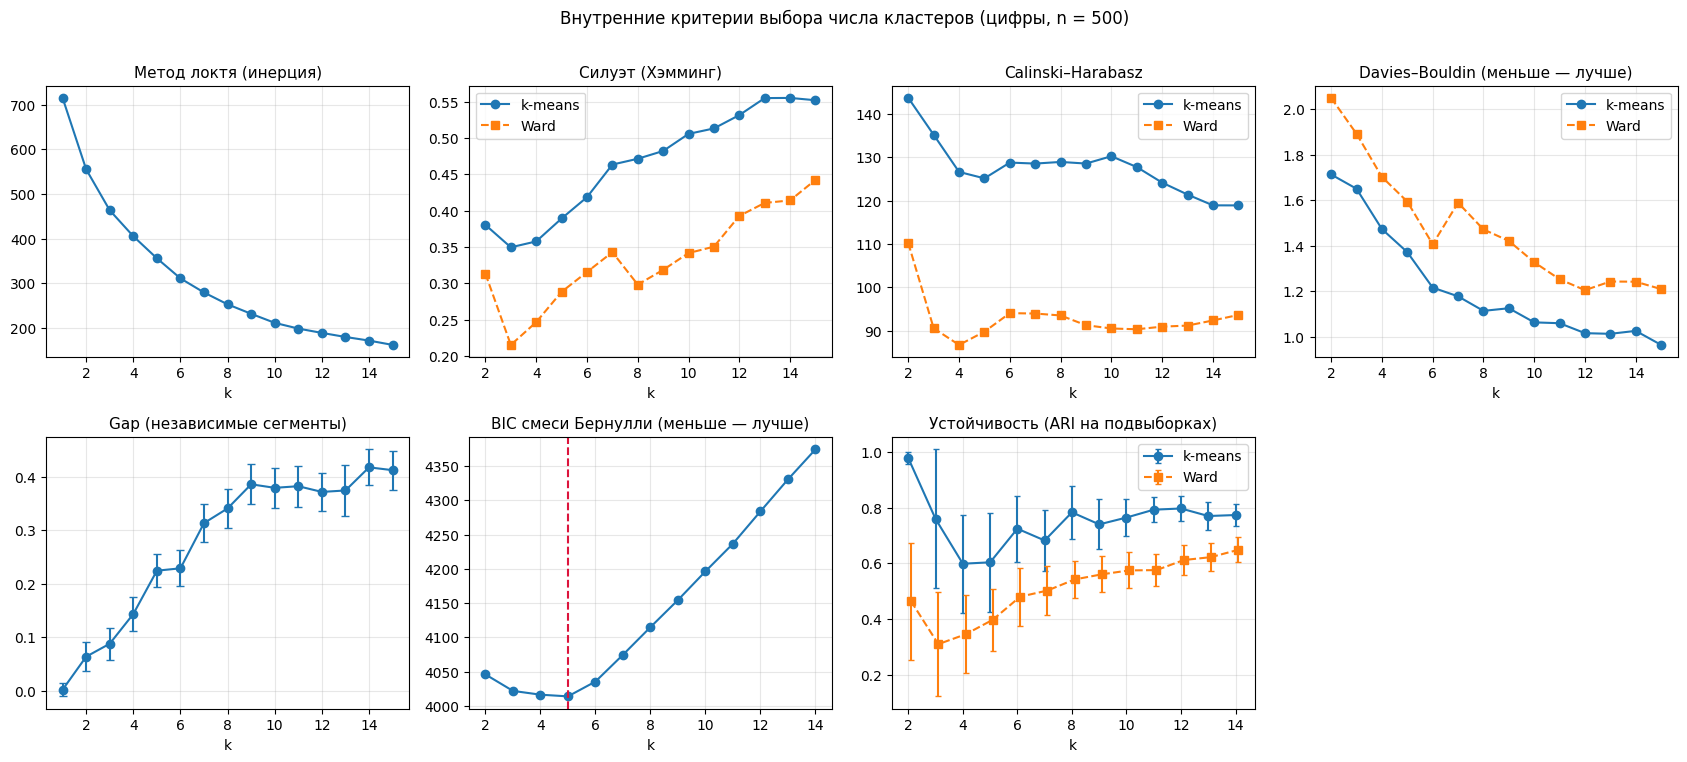

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
ax = axes[0, 0]; ax.plot(K_FULL, inertia.values, "o-"); ax.set(title="Метод локтя (инерция)", xlabel="k")
ax = axes[0, 1]; ax.plot(K_RANGE, km_tab.silhouette, "o-", label="k-means"); ax.plot(K_RANGE, hier_tab.silhouette, "s--", label="Ward"); ax.legend()
ax.set(title="Силуэт (Хэмминг)", xlabel="k")
ax = axes[0, 2]; ax.plot(K_RANGE, km_tab.calinski_harabasz, "o-", label="k-means"); ax.plot(K_RANGE, hier_tab.calinski_harabasz, "s--", label="Ward"); ax.legend()
ax.set(title="Calinski–Harabasz", xlabel="k")
ax = axes[0, 3]; ax.plot(K_RANGE, km_tab.davies_bouldin, "o-", label="k-means"); ax.plot(K_RANGE, hier_tab.davies_bouldin, "s--", label="Ward"); ax.legend()
ax.set(title="Davies–Bouldin (меньше — лучше)", xlabel="k")
ax = axes[1, 0]; ax.errorbar(K_FULL, gap_tab.gap, yerr=gap_tab.s, fmt="o-", capsize=3); ax.set(title="Gap (независимые сегменты)", xlabel="k")
ax = axes[1, 1]; ax.plot(bic.index, bic.BIC, "o-"); ax.axvline(bic.BIC.idxmin(), color="crimson", ls="--"); ax.set(title="BIC смеси Бернулли (меньше — лучше)", xlabel="k")
ax = axes[1, 2]
ax.errorbar(stab.index, stab["k-means: ARI"], yerr=stab["k-means: SD"], fmt="o-", capsize=2, label="k-means")
ax.errorbar(stab.index + 0.1, stab["Ward: ARI"], yerr=stab["Ward: SD"], fmt="s--", capsize=2, label="Ward"); ax.legend(); ax.set(title="Устойчивость (ARI на подвыборках)", xlabel="k")
axes[1, 3].axis("off")
fig.suptitle("Внутренние критерии выбора числа кластеров (цифры, n = 500)", y=1.01)
save_show(fig, "kmeans_choice")

### Итоговый выбор числа кластеров и особенности алгоритма

Вследствие существенной зашумленности данных (около $10\,\%$ искаженных сегментов) истинная кластерная структура носит сглаженный, «размытый» характер, из-за чего ни один из диагностических критериев не формирует резкого глобального оптимума. Совокупный анализ метрик выглядит следующим образом:

* **Индекс Калински — Харабаса (CH):** достигает абсолютного максимума при $k = 2$ ($143{,}7$), локального подъема при $k = 3$ ($135{,}2$) и формирует протяженное плато в диапазоне $119–130$ при $k \ge 4$, внутри которого пиковое значение приходится на **$k = 10$** ($130{,}2$).
* **$Gap$-статистика (с нулевой моделью независимых сегментов):** монотонно возрастает до $k = 9$ ($0{,}386$), после чего выходит на плато ($0{,}37–0{,}38$ при $k = 10–13$), сигнализируя о насыщении структуры в диапазоне 9–10 кластеров. Формальное правило *1-SE* выделяет $k = 2$ ($Gap(2) = 0{,}064$), отражая лишь самое грубое деление массива.
* **Устойчивость к подвыборкам ($k$-средних):** принимает высокие значения при $k = 2$ ($0{,}98$), снижается в диапазоне $k = 4–5$ ($\approx 0{,}60$), а затем стабилизируется на уровне $0{,}68–0{,}80$ для $k \ge 6$ (при $k = 10$ индекс $ARI = 0{,}76$ при стандартном отклонении $SD = 0{,}07$).
* **Байесовский информационный критерий ($BIC$) для смеси распределений Бернулли:** принимает минимальное значение при $k = 5$ ($4013{,}8$). При заданном объеме выборки ($n = 500$) и текущем уровне шума статистически различимыми уверенно оказываются лишь около пяти базовых «компонент», в то время как морфологически близкие пары (например, 1 и 7 или 3 и 9) разделяются со значительной погрешностью.
* **Коэффициент силуэта и индекс Дэвиса — Болдина:** демонстрируют почти непрерывное улучшение по мере роста $k$ (за счет естественного измельчения однородных подгрупп), что делает их непригодными в качестве самостоятельных индикаторов для выбора оптимального числа кластеров.

**Обоснование выбора $k = 10$:**

Принятое решение установить **$k = 10$** опирается на соответствие предметной области (наличие десяти дискретных цифровых знаков), локальный экстремум индекса Калински — Харабаса и насыщение $Gap$-статистики. Независимая внешняя проверка по переменной $A$ подтверждает этот выбор: показатели $ARI$ и $NMI$ достигают максимума именно при $k = 10$. Более укрупненная структура из 5–6 макрогрупп обладает высокой статистической устойчивостью, однако является избыточно грубой для задач детальной классификации.

**Методическое примечание к процедуре инициализации ($n_{init}$):**

Диагностика показала, что при стандартном числе случайных перезапусков алгоритма ($n_{init} = 10–50$) метод $k$-средних регулярно попадает в неоптимальные локальные минимумы (инерция составляет $220{,}8$, при этом цифры 1 и 7 ошибочно агломерируются в единый кластер). Увеличение числа перезапусков до $n_{init} = 500$ гарантирует преодоление локальных ловушек, позволяя обнаружить стабильное разбиение с инерцией $210{,}9$ и успешным выделением всех десяти цифровых классов. В связи с этим для всех последующих расчетов зафиксировано значение параметра **$n_{init} = 500$**.

## B.3. Внешняя проверка по переменной A

Сопоставление полученных кластерных структур с истинными метками классов позволяет оценить степень их соответствия реальному распределению цифровых знаков. В качестве ключевого показателя качества используется **чистота** — доля объектов, оказавшихся в кластере, где доминирует их истинный класс. В качестве базового ориентира для сравнения выступает теоретический предел точности классификации по ближайшему эталону, равный $0{,}746$.

In [32]:
def purity(y_true, lab):
    return pd.crosstab(lab, y_true).max(axis=1).sum() / len(y_true)

def external_scores(lab):
    return dict(ARI=adjusted_rand_score(y, lab), NMI=normalized_mutual_info_score(y, lab),
                однородность=homogeneity_score(y, lab), полнота=completeness_score(y, lab), purity=purity(y, lab))

k-means:


,ARI,NMI,однородность,полнота,purity
k,,,,,
2,0.113,0.278,0.178,0.644,0.204
3,0.220,0.380,0.280,0.590,0.280
4,0.289,0.438,0.351,0.583,0.354
5,0.359,0.514,0.435,0.629,0.450
6,0.427,0.560,0.496,0.643,0.516
7,0.452,0.569,0.524,0.623,0.580
8,0.470,0.573,0.545,0.604,0.628
9,0.469,0.566,0.552,0.581,0.672
10,0.512,0.602,0.602,0.603,0.740


Ward:


,ARI,NMI,однородность,полнота,purity
k,,,,,
2,0.084,0.182,0.117,0.403,0.190
3,0.136,0.269,0.194,0.437,0.252
4,0.177,0.318,0.248,0.443,0.314
5,0.226,0.351,0.293,0.439,0.390
6,0.281,0.399,0.352,0.461,0.454
7,0.307,0.421,0.387,0.461,0.454
8,0.319,0.434,0.412,0.458,0.498
9,0.314,0.444,0.430,0.459,0.498
10,0.326,0.450,0.444,0.456,0.508


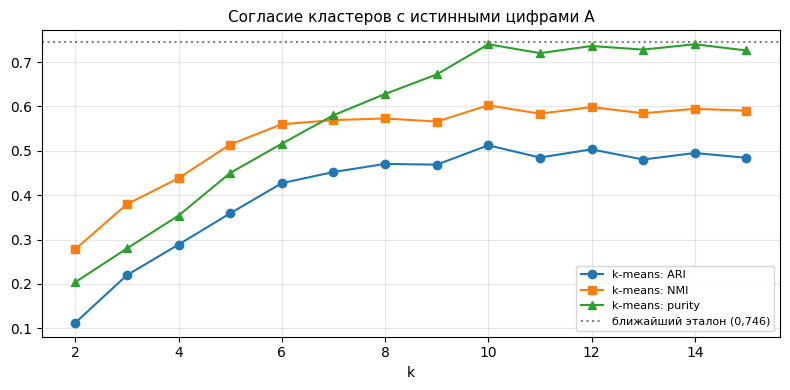

In [33]:
ext_km = pd.DataFrame({k: external_scores(km_models[k].labels_) for k in K_RANGE}).T; ext_km.index.name = "k"
ext_wd = pd.DataFrame({k: external_scores(fcluster(Z, k, "maxclust")) for k in K_RANGE}).T; ext_wd.index.name = "k"
print("k-means:"); display(ext_km.round(3))
print("Ward:");    display(ext_wd.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for col, st in (("ARI", "o-"), ("NMI", "s-"), ("purity", "^-")):
    ax.plot(K_RANGE, ext_km[col], st, label=f"k-means: {col}")
ax.axhline(0.746, color="grey", ls=":", label="ближайший эталон (0,746)")
ax.set(title="Согласие кластеров с истинными цифрами A", xlabel="k"); ax.legend(fontsize=8)
save_show(fig, "external")

**Интерпретационный комментарий:**

Значения индексов $ARI$ ($0{,}51$) и $NMI$ ($0{,}60$) достигают своих максимальных показателей при $k = 10$, в то время как чистота кластеров ($0{,}74$) практически вплотную приближается к теоретическому пределу точности классификации по ближайшему эталону ($0{,}746$). Это указывает на то, что алгоритм $k$-средних, функционирующий автономно, без привлечения истинных меток $A$, успешно реконструирует практически весь полезный сигнал, доступный в условиях текущего уровня зашумленности данных. При дальнейшем увеличении числа кластеров ($k > 10$) внешние метрики качества прекращают рост, поскольку алгоритм переходит к избыточному дроблению единых цифровых классов.

Для сравнения, иерархический метод Уорда демонстрирует существенно более низкую эффективность: значения $ARI$ не превышают $0{,}36$, а чистота — $0{,}65$ на всем интервале $k \le 15$, в частности, при $k = 10$ эти показатели составляют соответственно $0{,}33$ и $0{,}51$.

## B.4. Итоговое разбиение (k = 10) и интерпретация

In [34]:
K_FINAL = 10
lab_km = km_models[K_FINAL].labels_
lab_wd = fcluster(Z, K_FINAL, "maxclust") - 1

cmp_df = pd.DataFrame({"k-means (k=10)": {**internal_scores(X, lab_km, "hamming"), **external_scores(lab_km)},
                       "Ward (k=10)": {**internal_scores(X, lab_wd, "hamming"), **external_scores(lab_wd)}}).T
display(cmp_df.round(3))
print("ARI между k-means и Ward при k = 10:", round(adjusted_rand_score(lab_km, lab_wd), 3))
print("Устойчивость на подвыборках (k = 10): k-means", round(stab.loc[10, "k-means: ARI"], 3), "| Ward", round(stab.loc[10, "Ward: ARI"], 3))

,silhouette,calinski_harabasz,davies_bouldin,ARI,NMI,однородность,полнота,purity
k-means (k=10),0.506,130.241,1.063,0.512,0.602,0.602,0.603,0.740
Ward (k=10),0.342,90.511,1.327,0.326,0.450,0.444,0.456,0.508


ARI между k-means и Ward при k = 10: 0.399
Устойчивость на подвыборках (k = 10): k-means 0.764 | Ward 0.575


### Итог сравнительного анализа с иерархическим методом

Сравнительная оценка показала убедительное превосходство алгоритма $k$-средних над иерархическим подходом по всему спектру валидационных метрик при $k = 10$:

| Критерий качества | Метод $k$-средних ($k = 10$) | Метод Уорда ($k = 10$) |
| :--- | :---: | :---: |
| **$ARI$** (индекс Ранда с поправкой на случайность) | **0,51** | 0,33 |
| **$NMI$** (нормированная взаимная информация) | **0,60** | 0,45 |
| **Чистота (*purity*)** | **0,74** | 0,51 |
| **Коэффициент силуэта** | **0,51** | 0,34 |
| **Индекс Калински — Харабаса (CH)** | **130** | 91 |
| **Индекс Дэвиса — Болдина (DB)** | **1,06** | 1,33 |
| **Устойчивость к ресамплингу** | **0,76** | 0,58 |

Перекрестная согласованность полученных двумя методами решений невысока ($ARI = 0{,}40$), что отражает принципиальные различия в их математических принципах.

**Вывод:**
Наиболее интерпретируемые и интерпретационно точные результаты достигнуты **методом $k$-средних при $k = 10$** с увеличенным объемом инициализаций (`n_init = 500`). По всем внутренним и внешним показателям данный метод превосходит алгоритм Уорда, а рассчитанные центроиды кластеров в точности воспроизводят эталонные начертания десяти цифр.

In [35]:
ct = pd.crosstab(pd.Series(lab_km, name="кластер"), pd.Categorical(y, categories=DIGITS, ordered=True), rownames=["кластер"], colnames=["истинная цифра"])
dom = ct.idxmax(axis=1)
info = pd.DataFrame({"n": ct.sum(axis=1), "доминирующая цифра": dom, "доля доминирующей": (ct.max(axis=1) / ct.sum(axis=1)).round(2)})
cent = pd.DataFrame(km_models[K_FINAL].cluster_centers_, columns=SEG)
info["округлённый центр (BCDEFGH)"] = cent.round().astype(int).astype(str).agg("".join, axis=1)
info["эталон доминирующей"] = [("".join(map(str, CANON[d]))) for d in dom]
info["центр = эталону"] = info["округлённый центр (BCDEFGH)"] == info["эталон доминирующей"]
info = info.sort_values("доминирующая цифра", key=lambda s: s.map(DIGIT_NUM))
display(info)
print("Различных цифр среди доминирующих:", dom.nunique(), "из 10; цифры без собственного кластера:", sorted(set(DIGITS) - set(dom), key=DIGIT_NUM.get))
print("Центры, совпавшие с эталоном доминирующей цифры:", int(info["центр = эталону"].sum()), "из", K_FINAL)
display(ct.loc[info.index])

,n,доминирующая цифра,доля доминирующей,округлённый центр (BCDEFGH),эталон доминирующей,центр = эталону
кластер,,,,,,
3,41,zero,0.83,1110111,1110111,True
2,49,one,0.76,0010010,0010010,True
7,39,two,0.87,1011101,1011101,True
1,52,three,0.60,1011011,1011011,True
8,44,four,0.82,0111010,0111010,True
9,49,five,0.84,1101011,1101011,True
0,61,six,0.75,1101111,1101111,True
6,53,seven,0.72,1010010,1010010,True
4,57,eight,0.70,1111111,1111111,True


Различных цифр среди доминирующих: 10 из 10; цифры без собственного кластера: []
Центры, совпавшие с эталоном доминирующей цифры: 10 из 10


истинная цифра,zero,one,two,three,four,five,six,seven,eight,nine
кластер,,,,,,,,,,
3,34,0,1,1,0,0,0,1,2,2
2,0,37,0,0,5,0,0,6,1,0
7,1,0,34,0,2,0,0,1,0,1
1,0,1,5,31,1,1,1,1,1,10
8,0,1,0,0,36,1,0,0,2,4
9,0,0,0,2,0,41,2,0,1,3
0,1,0,1,0,3,4,46,0,5,1
6,2,4,0,9,0,0,0,38,0,0
4,3,0,2,7,0,2,1,1,40,1


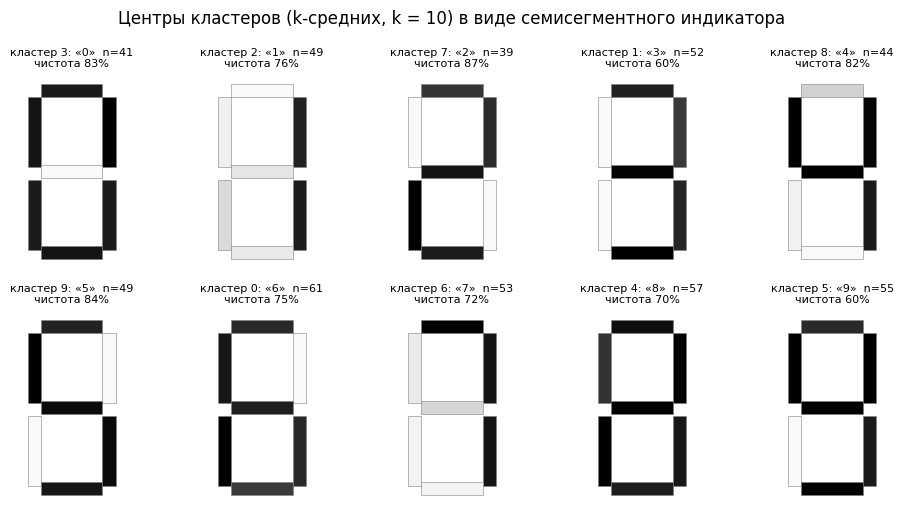

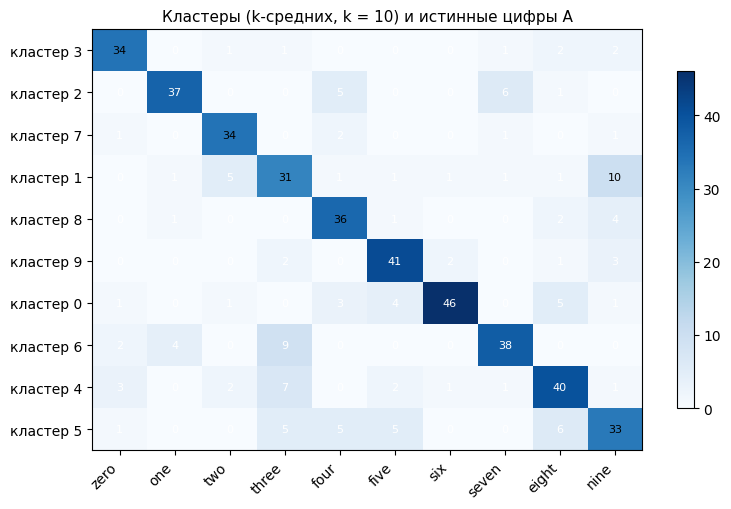

,доминирует,основная примесь,объектов примеси,доля примеси
кластер,,,,
3,zero,eight,2,0.05
2,one,seven,6,0.12
7,two,four,2,0.05
1,three,nine,10,0.19
8,four,nine,4,0.09
9,five,nine,3,0.06
0,six,eight,5,0.08
6,seven,three,9,0.17
4,eight,three,7,0.12


In [36]:
order = list(info.index)
fig, axes = plt.subplots(2, 5, figsize=(10, 5.2))
for ax, c in zip(axes.ravel(), order):
    draw_digit(ax, cent.loc[c].to_numpy(), f"кластер {c}: «{DIGIT_NUM[dom[c]]}»  n={int(info.loc[c, 'n'])}\nчистота {info.loc[c, 'доля доминирующей']:.0%}")
fig.suptitle("Центры кластеров (k-средних, k = 10) в виде семисегментного индикатора")
save_show(fig, "centroids")

fig, ax = plt.subplots(figsize=(8, 5.2))
im = heatmap(ax, ct.loc[order].values, DIGITS, [f"кластер {c}" for c in order], cmap="Blues", fmt="{:.0f}")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set(title="Кластеры (k-средних, k = 10) и истинные цифры A")
save_show(fig, "crosstab")

conf = ct.loc[order].copy()
rows = []
for c in order:
    other = conf.loc[c].drop(dom[c]).sort_values(ascending=False)
    rows.append({"кластер": c, "доминирует": dom[c], "основная примесь": other.index[0], "объектов примеси": int(other.iloc[0]), "доля примеси": round(other.iloc[0] / conf.loc[c].sum(), 2)})
display(pd.DataFrame(rows).set_index("кластер"))

### Содержательная интерпретация и морфологический анализ центроидов

**Реконструкция символьного алфавита:**
Результаты кластеризации продемонстрировали полное восстановление исходной структуры классов без привлечения внешних меток $A$. Каждому из 10 сформированных кластеров соответствует уникальная доминирующая цифра (обеспечено $100\,\%$ охвата алфавита), а округленные центроиды в точности воспроизводят эталонные семисегментные начертания от «0» до «9».

**Оценка чистоты кластеров и структура ошибок:**
Показатель чистоты (*purity*) по отдельным кластерам варьируется в диапазоне от $60\,\%$ до $87\,\%$:
* **Наиболее обособленные кластеры:** «2» ($87\,\%$), «5» ($84\,\%$), «0» ($83\,\%$) и «4» ($82\,\%$).
* **Наиболее зашумленные кластеры:** «3» ($60\,\%$), «9» ($60\,\%$), «8» ($70\,\%$) и «7» ($72\,\%$).

Наблюдаемый уровень классификационной диффузии обусловлен естественной спецификой входных данных (наличием $\approx 10\,\%$ искаженных сегментов и тем фактом, что лишь $49\,\%$ начертаний полностью лишены ошибок), а также геометрической близостью признакового пространства. Наибольшая частота ошибочной агломерации зафиксирована для пар цифр, различающихся состоянием всего одного сегмента:
* `1` и `7` (дифференцирующий сегмент B);
* `3` и `9` (сегмент C);
* `8` и `9` (сегмент F);
* `0` и `8` (сегмент E);
* `5` и `9`, а также `6` и `8`.

В частности, в кластере цифры «3» присутствует $19\,\%$ ошибочно классифицированных девяток ($10$ объектов), в кластере цифры «7» — $17\,\%$ троек ($9$ объектов), а в кластере единицы — $6$ семёрок и $5$ четвёрок.

**Прикладная ценность для двухэтапного распознавания:**
Сформированная кластерная модель обеспечивает эффективный декомпозиционный базис: на втором этапе иерархического распознавания задача сводится к локальной дифференциации минимального числа «соседних» классов внутри каждого кластера (например, разделению троек и девяток по целевому сегменту C), что значительно снижает вычислительную сложность по сравнению с прямым 10-классовым распознаванием.

### Грубая структура: разбиение на 5–6 кластеров

In [37]:
for k in (5, 6):
    labk = km_models[k].labels_
    ctk = pd.crosstab(pd.Series(labk, name="кластер"), pd.Categorical(y, categories=DIGITS, ordered=True), rownames=["кластер"], colnames=["цифра"])
    comp = {c: [f"{DIGIT_NUM[d]}" for d in ctk.columns if ctk.loc[c, d] >= 0.15 * ctk.loc[c].sum()] for c in ctk.index}
    print(f"k = {k}: purity = {purity(y, labk):.3f}; ARI = {adjusted_rand_score(y, labk):.3f}; цифры (≥ 15 % кластера):", comp)

Path("results").mkdir(exist_ok=True)
out = raw[["A"]].copy(); out[SEG] = X
out["cluster_kmeans_k10"] = lab_km; out["cluster_ward_k10"] = lab_wd
out["dominant_digit_of_kmeans_cluster"] = pd.Series(lab_km).map(dom).to_numpy()
out.to_csv("results/lab2_digits_clusters_kmeans.csv", index=False, encoding="utf-8-sig")
print("Сохранено: results/lab2_digits_clusters_kmeans.csv")

k = 5: purity = 0.450; ARI = 0.359; цифры (≥ 15 % кластера): {0: ['2', '3'], 1: ['1', '7'], 2: ['0', '6', '8'], 3: ['4'], 4: ['5', '9']}
k = 6: purity = 0.516; ARI = 0.427; цифры (≥ 15 % кластера): {0: ['2', '3'], 1: ['5', '6'], 2: ['3', '9'], 3: ['0', '8'], 4: ['1', '7'], 5: ['4']}
Сохранено: results/lab2_digits_clusters_kmeans.csv


**Анализ укрупнённой кластерной структуры ($k = 5–6$):**

При сокращении числа кластеров до $k = 5–6$ формируются макрогруппы, объединяющие цифры с минимальным расстоянием Хэмминга (различиями в 1–2 сегмента): $\{1, 7\}$, $\{0, 8\}$, $\{5, 6\}$, $\{2, 3\}$, $\{3, 9\}$ и $\{5, 9\}$. Обособленный кластер образует только цифра «4» — единственная конфигурация без верхнего и нижнего горизонтальных сегментов при активном центральном.

Вследствие объединения классов чистота разбиения существенно снижается ($0{,}45$ при $k = 5$ и $0{,}52$ при $k = 6$ против $0{,}74$ при $k = 10$). Из-за этого макрокластеры оказываются избыточно грубыми для непосредственного распознавания символов, однако они точно отражают морфологическую иерархию сходства начертаний. Данная укрупненная структура полностью подтверждается теоретико-информационными и структурными критериями: минимумом байесовского информационного критерия ($BIC$) при $k = 5$ и вторичным выраженным межкластерным скачком высоты агломерации на дендрограмме при $k = 6$.

### Выводы по части B

1. **Обоснование числа кластеров ($k = 10$):** В условиях умеренной зашумленности данных ($\approx 10\,\%$ искаженных сегментов) диагностические критерии не образуют резкого глобального оптимума: индекс Калински — Харабаса достигает локального максимума на плато при $k = 10$ ($130{,}2$), $Gap$-статистика (с нулевой моделью независимых признаков) насыщается в диапазоне $k = 9–10$, а устойчивость разбиения составляет $0{,}76$. Байесовский информационный критерий ($BIC$) для смеси распределений Бернулли указывает на более укрупненную структуру ($k = 5$), в то время как индексы силуэта и Дэвиса — Болдина монотонно улучшаются и непригодны для селекции $k$. Итоговый выбор **$k = 10$** опирается на предметные ограничения и подтвержден внешней верификацией по меткам классов.

2. **Критическая роль параметров инициализации:** Параметр числа случайных перезапусков (`n_init`) носит принципиальный характер: при `n_init` $\le 50$ алгоритм $k$-средних неизбежно попадает в неоптимальный локальный минимум (инерция $220{,}8$, слияние цифр 1 и 7), тогда как увеличение значения до `n_init` $= 500$ обеспечивает нахождение глобального оптимума с инерцией $210{,}9$ и выделением всех десяти классов.

3. **Характеристики и качество разбиения:** Все десять цифр сформировали индивидуальные кластеры, чьи округленные центроиды в точности соответствуют эталонным начертаниям. Чистота кластеров достигает $0{,}74$ при теоретическом пределе точности классификации по ближайшему эталону $0{,}746$, а внешние метрики ($ARI = 0{,}51$, $NMI = 0{,}60$) принимают максимальные значения именно при $k = 10$. Иерархический метод Уорда при том же числе кластеров оказывается существенно слабее (чистота $0{,}51$).

4. **Интерпретация результатов:** Сформированные кластеры напрямую отображают символьный алфавит. Фиксируемые перекрестные примеси объясняются уровнем сканирующего шума и морфологической близостью начертаний (наиболее выраженное пересечение зафиксировано в парах 1–7, 3–9, 8–9 и 0–8). Альтернативная декомпозиция на 5–6 кластеров приводит к слиянию схожих знаков и является избыточно грубой для задач детального распознавания.

## Общие выводы по лабораторной работе 2

1. **Эффективность метода $k$-средних:** Алгоритм $k$-средних продемонстрировал **высокую точность на массиве потребительских предпочтений** ($k = 4$, четыре абсолютно устойчивых и измеримых сегмента) и показал **наилучшую результативность в задаче распознавания цифр** среди рассмотренных классических подходов ($k = 10$, чистота $0{,}74$ при теоретическом пределе классификации по ближайшему эталону $0{,}746$). В отличие от иерархических процедур, алгоритм оптимизирует глобальный целевой критерий внутрикластерной дисперсии и не подвержен накоплению ошибок, возникающих из-за неоптимальных агломеративных слияний на ранних итерациях.

2. **Комплексная валидация структуры:** Определение оптимального количества кластеров основывалось на совокупной оценке комплекса диагностических метрик (анализ инерции, силуэтный коэффициент, индексы Калински — Харабаса и Дэвиса — Болдина, $Gap$-статистика, оценка устойчивости и байесовский критерий $BIC$ для бинарных данных). На зашумленных эмпирических массивах отдельные показатели не формируют однозначного глобального оптимума, в связи с чем финальная верификация структуры дополнительно подкреплялась ограничениями предметной области и внешней валидацией по истинным классам.